
# FlightAura — Dataset Audit and Exploration

## Objective
Inspect the airline passenger reviews dataset before performing preprocessing or model training.

## Tasks
1. Load and inspect the dataset.
2. Identify numerical, categorical, textual and date columns.
3. Inspect missing values and duplicates.
4. Detect incorrectly assigned data types.
5. Examine unique values and inconsistent categories.
6. Inspect rating and recommendation distributions.
7. Analyze review lengths.
8. Identify potential data quality issues.

**Important:** This notebook will not modify the original dataset.

In [1]:
# Cell 2 — Import libraries

# Data manipulation
import pandas as pd
import numpy as np

# File handling
from pathlib import Path

# Visualization
import matplotlib.pyplot as plt
import seaborn as sns

# Warnings and configuration
import warnings
warnings.filterwarnings("ignore")

# Reproducibility
RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# Display configuration
pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 100)
pd.set_option("display.max_colwidth", 120)

sns.set_theme(style="whitegrid")

print("Libraries imported successfully!")
print("Pandas version:", pd.__version__)
print("NumPy version:", np.__version__)


Libraries imported successfully!
Pandas version: 2.3.3
NumPy version: 1.26.4


In [4]:
# Cell 3 — Define dataset path

# Project directory
PROJECT_DIR = Path.cwd().parent

# Dataset directory
DATASET_DIR = PROJECT_DIR / "dataset"

# Dataset file
DATA_PATH = DATASET_DIR / "airlines_reviews.csv"

print("Project directory:", PROJECT_DIR.resolve())
print("Dataset directory:", DATASET_DIR.resolve())
print("Dataset path:", DATA_PATH.resolve())
print("Dataset exists:", DATA_PATH.exists())

# Display CSV files available in dataset folder
csv_files = list(DATASET_DIR.glob("*.csv"))

print("\nCSV files found:")

for file in csv_files:
    print("-", file.name)


Project directory: C:\Users\HP\Documents\Projects\FlightAura
Dataset directory: C:\Users\HP\Documents\Projects\FlightAura\dataset
Dataset path: C:\Users\HP\Documents\Projects\FlightAura\dataset\airlines_reviews.csv
Dataset exists: True

CSV files found:
- airlines_reviews.csv


In [5]:
# Cell 4 — Load dataset
# Load original dataset
df = pd.read_csv(DATA_PATH, low_memory=False)

# Preserve original dataset shape
original_shape = df.shape

print("Dataset loaded successfully!")
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

display(df.head())


Dataset loaded successfully!
Number of rows: 8100
Number of columns: 17


,Title,Name,Review Date,Airline,Verified,Reviews,Type of Traveller,Month Flown,Route,Class,Seat Comfort,Staff Service,Food & Beverages,Inflight Entertainment,Value For Money,Overall Rating,Recommended
0,Flight was amazing,Alison Soetantyo,2024-03-01,Singapore Airlines,True,"Flight was amazing. The crew onboard this flight were very welcoming, and gave a good atmosphere. The crew serving...",Solo Leisure,December 2023,Jakarta to Singapore,Business Class,4,4,4,4,4,9,yes
1,seats on this aircraft are dreadful,Robert Watson,2024-02-21,Singapore Airlines,True,Booking an emergency exit seat still meant huge discomfort in a seat far too narrow and poor padding meaning back ...,Solo Leisure,February 2024,Phuket to Singapore,Economy Class,5,3,4,4,1,3,no
2,Food was plentiful and tasty,S Han,2024-02-20,Singapore Airlines,True,Excellent performance on all fronts. I would definitely choose to use this airline again. The aircraft is well-mai...,Family Leisure,February 2024,Siem Reap to Singapore,Economy Class,1,5,2,1,5,10,yes
3,“how much food was available,D Laynes,2024-02-19,Singapore Airlines,True,Pretty comfortable flight considering I was flying in economy class in one of the older aircraft in their fleet whi...,Solo Leisure,February 2024,Singapore to London Heathrow,Economy Class,5,5,5,5,5,10,yes
4,“service was consistently good”,A Othman,2024-02-19,Singapore Airlines,True,The service was consistently good from start to finish. The cabin crew showcased the friendly Singaporean culture a...,Family Leisure,February 2024,Singapore to Phnom Penh,Economy Class,5,5,5,5,5,10,yes


In [6]:
# Cell 5 — Inspect first and last records
print("FIRST 5 RECORDS")
display(df.head())

print("\nLAST 5 RECORDS")
display(df.tail())


FIRST 5 RECORDS


,Title,Name,Review Date,Airline,Verified,Reviews,Type of Traveller,Month Flown,Route,Class,Seat Comfort,Staff Service,Food & Beverages,Inflight Entertainment,Value For Money,Overall Rating,Recommended
0,Flight was amazing,Alison Soetantyo,2024-03-01,Singapore Airlines,True,"Flight was amazing. The crew onboard this flight were very welcoming, and gave a good atmosphere. The crew serving...",Solo Leisure,December 2023,Jakarta to Singapore,Business Class,4,4,4,4,4,9,yes
1,seats on this aircraft are dreadful,Robert Watson,2024-02-21,Singapore Airlines,True,Booking an emergency exit seat still meant huge discomfort in a seat far too narrow and poor padding meaning back ...,Solo Leisure,February 2024,Phuket to Singapore,Economy Class,5,3,4,4,1,3,no
2,Food was plentiful and tasty,S Han,2024-02-20,Singapore Airlines,True,Excellent performance on all fronts. I would definitely choose to use this airline again. The aircraft is well-mai...,Family Leisure,February 2024,Siem Reap to Singapore,Economy Class,1,5,2,1,5,10,yes
3,“how much food was available,D Laynes,2024-02-19,Singapore Airlines,True,Pretty comfortable flight considering I was flying in economy class in one of the older aircraft in their fleet whi...,Solo Leisure,February 2024,Singapore to London Heathrow,Economy Class,5,5,5,5,5,10,yes
4,“service was consistently good”,A Othman,2024-02-19,Singapore Airlines,True,The service was consistently good from start to finish. The cabin crew showcased the friendly Singaporean culture a...,Family Leisure,February 2024,Singapore to Phnom Penh,Economy Class,5,5,5,5,5,10,yes



LAST 5 RECORDS


,Title,Name,Review Date,Airline,Verified,Reviews,Type of Traveller,Month Flown,Route,Class,Seat Comfort,Staff Service,Food & Beverages,Inflight Entertainment,Value For Money,Overall Rating,Recommended
8095,an uneventful flight,N Vickers,2016-06-20,Korean Air,True,"KE124, Brisbane to Incheon (A330) and KE867, Incheon to Ulaanbaatar (A330) with Korean Air. An uneventful flight w...",Business,June 2016,BNE to ULN via ICN,Economy Class,5,4,5,3,4,7,yes
8096,Korean Air always impresses,Kim Holloway,2016-06-12,Korean Air,False,Our recent flight was our fourth trip to the UK in 6 years from Sydney to London via Seoul and as usual Korean Air...,Couple Leisure,June 2016,SYD to LHR via ICN,Economy Class,3,5,5,4,5,10,yes
8097,didn’t offer anything,C Clark,2016-06-06,Korean Air,True,I flew Korean Air from Bali to Seoul in Prestige Class (Business Class). Though it is one of the longest intra-Asi...,Business,April 2016,DPS to ICN,Business Class,4,5,5,5,1,2,no
8098,appreciated the service onboard,E Petan,2016-04-21,Korean Air,False,"Seoul to Paris with Korean Air. I am traveling with my triathlon bike, which is sometimes an issue for some airlin...",Business,April 2016,ICN to CDG,Business Class,5,1,3,4,5,10,yes
8099,genuinely friendly staff,D Lanor,2016-04-12,Korean Air,False,The 13 hour flight in Business class from Seoul to Toronto onboard Korean Air KE73 turned out to be a real pleasur...,Business,April 2016,ICN to YYZ,Business Class,3,5,3,3,5,10,yes


In [7]:
# Cell 6 — Dataset structure and data types
print("DATASET INFORMATION")
df.info()

print("\nDATA TYPES")
display(df.dtypes.to_frame(name="Data Type"))

print("\nTOTAL MEMORY USAGE")
print(round(df.memory_usage(deep=True).sum() / (1024 ** 2), 2), "MB")


DATASET INFORMATION
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 8100 entries, 0 to 8099
Data columns (total 17 columns):
 #   Column                  Non-Null Count  Dtype 
---  ------                  --------------  ----- 
 0   Title                   8100 non-null   object
 1   Name                    8100 non-null   object
 2   Review Date             8100 non-null   object
 3   Airline                 8100 non-null   object
 4   Verified                8100 non-null   object
 5   Reviews                 8100 non-null   object
 6   Type of Traveller       8100 non-null   object
 7   Month Flown             8100 non-null   object
 8   Route                   8100 non-null   object
 9   Class                   8100 non-null   object
 10  Seat Comfort            8100 non-null   int64 
 11  Staff Service           8100 non-null   int64 
 12  Food & Beverages        8100 non-null   int64 
 13  Inflight Entertainment  8100 non-null   int64 
 14  Value For Money         8100 non-nul

,Data Type
Title,object
Name,object
Review Date,object
Airline,object
Verified,object
Reviews,object
Type of Traveller,object
Month Flown,object
Route,object
Class,object



TOTAL MEMORY USAGE
13.9 MB


In [8]:
# Cell 7 — Separate numerical, categorical and other columns


numeric_columns = df.select_dtypes(include=["number"]).columns.tolist()

categorical_columns = df.select_dtypes(
    include=["object", "category", "bool"]
).columns.tolist()

datetime_columns = df.select_dtypes(
    include=["datetime", "datetimetz"]
).columns.tolist()

print("NUMERICAL COLUMNS")
print(numeric_columns)

print("\nCATEGORICAL / OBJECT COLUMNS")
print(categorical_columns)

print("\nDATETIME COLUMNS")
print(datetime_columns)

print("\nTOTAL COLUMNS:", len(df.columns))


NUMERICAL COLUMNS
['Seat Comfort', 'Staff Service', 'Food & Beverages', 'Inflight Entertainment', 'Value For Money', 'Overall Rating']

CATEGORICAL / OBJECT COLUMNS
['Title', 'Name', 'Review Date', 'Airline', 'Verified', 'Reviews', 'Type of Traveller', 'Month Flown', 'Route', 'Class', 'Recommended']

DATETIME COLUMNS
[]

TOTAL COLUMNS: 17


In [9]:
# Cell 8 — Detailed column audit


column_audit = pd.DataFrame({
    "Column": df.columns,
    "Data Type": [str(df[col].dtype) for col in df.columns],
    "Non-Null Count": [df[col].notna().sum() for col in df.columns],
    "Missing Count": [df[col].isna().sum() for col in df.columns],
    "Missing Percentage": [
        round(df[col].isna().mean() * 100, 2)
        for col in df.columns
    ],
    "Unique Values": [df[col].nunique(dropna=True) for col in df.columns],
    "Memory MB": [
        round(df[col].memory_usage(deep=True) / (1024 ** 2), 3)
        for col in df.columns
    ]
})

display(column_audit)


,Column,Data Type,Non-Null Count,Missing Count,Missing Percentage,Unique Values,Memory MB
0,Title,object,8100,0,0.0,7614,0.671
1,Name,object,8100,0,0.0,6583,0.524
2,Review Date,object,8100,0,0.0,2549,0.518
3,Airline,object,8100,0,0.0,10,0.547
4,Verified,object,8100,0,0.0,5,0.473
5,Reviews,object,8100,0,0.0,8099,9.599
6,Type of Traveller,object,8100,0,0.0,4,0.534
7,Month Flown,object,8100,0,0.0,107,0.527
8,Route,object,8100,0,0.0,5566,0.627
9,Class,object,8100,0,0.0,4,0.543


In [10]:
# Cell 9 — Missing-value analysis


missing_audit = pd.DataFrame({
    "Missing Count": df.isnull().sum(),
    "Missing Percentage": (df.isnull().mean() * 100).round(2),
    "Available Count": df.notnull().sum()
})

missing_audit = missing_audit.sort_values(
    by="Missing Percentage",
    ascending=False
)

display(missing_audit)

print("Total missing cells:", df.isnull().sum().sum())
print("Total missing percentage:",
      round(df.isnull().sum().sum() / df.size * 100, 2), "%")


,Missing Count,Missing Percentage,Available Count
Title,0,0.0,8100
Class,0,0.0,8100
Overall Rating,0,0.0,8100
Value For Money,0,0.0,8100
Inflight Entertainment,0,0.0,8100
Food & Beverages,0,0.0,8100
Staff Service,0,0.0,8100
Seat Comfort,0,0.0,8100
Route,0,0.0,8100
Name,0,0.0,8100


Total missing cells: 0
Total missing percentage: 0.0 %


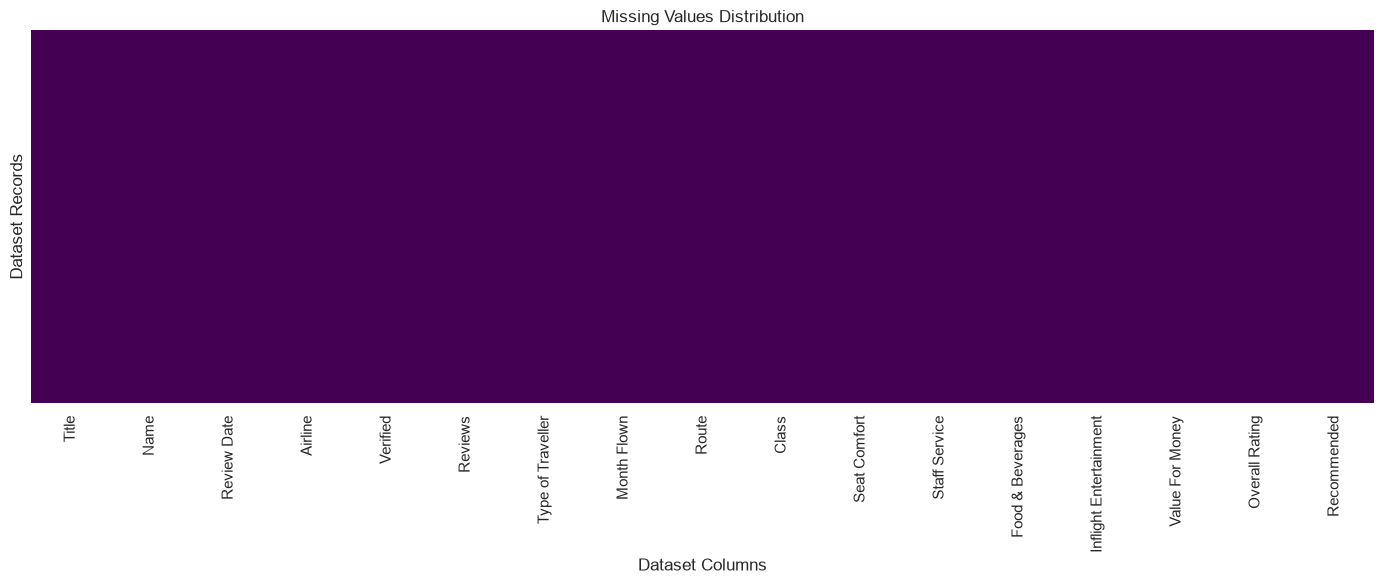

In [11]:
# Cell 10 — Visualize missing values


plt.figure(figsize=(14, 6))

sns.heatmap(
    df.isnull(),
    cbar=False,
    yticklabels=False,
    cmap="viridis"
)

plt.title("Missing Values Distribution")
plt.xlabel("Dataset Columns")
plt.ylabel("Dataset Records")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()


In [12]:
# Cell 11 — Duplicate analysis

duplicate_count = df.duplicated().sum()

print("Total duplicate rows:", duplicate_count)
print("Duplicate percentage:",
      round(duplicate_count / len(df) * 100, 2), "%")

print("\nCompletely empty rows:", df.isnull().all(axis=1).sum())

# Display duplicate examples without removing them
if duplicate_count > 0:
    display(df[df.duplicated(keep=False)].head(10))


Total duplicate rows: 0
Duplicate percentage: 0.0 %

Completely empty rows: 0


In [13]:
# Cell 12 — Unique values for every column


for col in df.columns:

    print("\n" + "=" * 80)
    print("COLUMN:", col)
    print("DATA TYPE:", df[col].dtype)
    print("UNIQUE COUNT:", df[col].nunique(dropna=True))

    print("\nTOP 20 VALUES:")
    display(df[col].value_counts(dropna=False).head(20))



COLUMN: Title
DATA TYPE: object
UNIQUE COUNT: 7614

TOP 20 VALUES:


Title
Turkish Airlines customer review      11
Qatar Airways customer review         11
worst customer service                 9
a pleasant experience                  9
seats were comfortable                 8
a very good experience                 8
Terrible customer service              7
terrible customer service              7
never fly with them again              7
one of the best airlines               7
service was excellent                  7
the worst customer service             7
Singapore Airlines customer review     6
very disappointed                      6
Excellent service                      6
seat was comfortable                   6
an excellent experience                6
a great experience                     6
Emirates customer review               6
I was very impressed                   6
Name: count, dtype: int64


COLUMN: Name
DATA TYPE: object
UNIQUE COUNT: 6583

TOP 20 VALUES:


Name
Michael Schade      44
Anders Pedersen     40
Michel Perrin       29
Alwaleed Althani    27
Elaine Loh          23
T Eldem             21
L Tran              21
R Sanyal            16
Francis Wong        15
Mohamed Alkowari    15
C Han               14
C Hoffmann          14
A Wong              14
Filippo Bertoni     13
Rajan Parrikar      13
T Merter            12
Craig Cutts         12
Zafrullah Hamzah    12
Doug Dumpa          12
John Duffus         12
Name: count, dtype: int64


COLUMN: Review Date
DATA TYPE: object
UNIQUE COUNT: 2549

TOP 20 VALUES:


Review Date
2017-12-18    12
2018-10-17    11
2019-10-16    11
2018-09-18    11
2019-09-22    11
2023-09-17    10
2019-02-26    10
2017-01-05    10
2017-12-31    10
2017-11-06    10
2018-02-26    10
2017-11-20    10
2019-09-23    10
2019-04-10    10
2017-03-10    10
2018-04-23    10
2023-09-18    10
2019-08-31     9
2022-09-05     9
2018-01-10     9
Name: count, dtype: int64

... (24 outputs left out)


COLUMN: Overall Rating
DATA TYPE: int64
UNIQUE COUNT: 10

TOP 20 VALUES:


Overall Rating
1     1808
10    1610
9     1054
8      742
2      692
3      522
7      509
5      436
4      381
6      346
Name: count, dtype: int64


COLUMN: Recommended
DATA TYPE: object
UNIQUE COUNT: 2

TOP 20 VALUES:


Recommended
yes    4287
no     3813
Name: count, dtype: int64

In [14]:
# Cell 13 — Identify object columns that might be numerical


numeric_like_results = []

for col in df.select_dtypes(include=["object", "category"]).columns:

    original = df[col].astype("string").str.strip()

    non_empty = original.notna() & original.ne("")

    converted = pd.to_numeric(original, errors="coerce")

    valid_numeric = converted[non_empty].notna().sum()
    total_values = non_empty.sum()

    numeric_like_results.append({
        "Column": col,
        "Original Data Type": str(df[col].dtype),
        "Non-Empty Values": total_values,
        "Numeric Values": valid_numeric,
        "Numeric Percentage": round(
            valid_numeric / total_values * 100, 2
        ) if total_values else 0,
        "Non-Numeric Examples": original[
            non_empty & converted.isna()
        ].drop_duplicates().head(10).tolist()
    })

numeric_like_audit = pd.DataFrame(numeric_like_results)

display(numeric_like_audit)


,Column,Original Data Type,Non-Empty Values,Numeric Values,Numeric Percentage,Non-Numeric Examples
0,Title,object,8100,0,0.0,"[Flight was amazing, seats on this aircraft are dreadful, Food was plentiful and tasty, “how much food was available..."
1,Name,object,8100,0,0.0,"[Alison Soetantyo, Robert Watson, S Han, D Laynes, A Othman, S Holger, A Jabil, A Kalarsan, S Dayle, J Hassin]"
2,Review Date,object,8100,0,0.0,"[2024-03-01, 2024-02-21, 2024-02-20, 2024-02-19, 2024-02-18, 2024-02-17, 2024-02-16, 2024-02-09, 2024-02-01, 2024-01..."
3,Airline,object,8100,0,0.0,"[Singapore Airlines, Qatar Airways, All Nippon Airways, Emirates, Japan Airlines, Turkish Airlines, Air France, Cath..."
4,Verified,object,8100,0,0.0,"[True, False, *Unverified*, NotVerified, we do appreciate you bringing this matter to our attention. Please accept m..."
5,Reviews,object,8100,0,0.0,"[Flight was amazing. The crew onboard this flight were very welcoming, and gave a good atmosphere. The crew serving ..."
6,Type of Traveller,object,8100,0,0.0,"[Solo Leisure, Family Leisure, Business, Couple Leisure]"
7,Month Flown,object,8100,0,0.0,"[December 2023, February 2024, January 2024, November 2023, September 2023, October 2023, May 2023, August 2023, Jun..."
8,Route,object,8100,0,0.0,"[Jakarta to Singapore, Phuket to Singapore, Siem Reap to Singapore, Singapore to London Heathrow, Singapore to Phnom..."
9,Class,object,8100,0,0.0,"[Business Class, Economy Class, Premium Economy, First Class]"


In [15]:
# Cell 14 — Identify numerical columns that might be categorical


numeric_category_results = []

for col in df.select_dtypes(include=["number"]).columns:

    unique_values = df[col].dropna().unique()

    numeric_category_results.append({
        "Column": col,
        "Data Type": str(df[col].dtype),
        "Unique Count": len(unique_values),
        "Unique Values": sorted(
            [str(x) for x in unique_values]
        )[:30]
    })

numeric_category_audit = pd.DataFrame(numeric_category_results)

display(
    numeric_category_audit.sort_values(
        by="Unique Count",
        ascending=True
    )
)


,Column,Data Type,Unique Count,Unique Values
0,Seat Comfort,int64,5,"[1, 2, 3, 4, 5]"
1,Staff Service,int64,5,"[1, 2, 3, 4, 5]"
2,Food & Beverages,int64,5,"[1, 2, 3, 4, 5]"
4,Value For Money,int64,5,"[1, 2, 3, 4, 5]"
3,Inflight Entertainment,int64,6,"[0, 1, 2, 3, 4, 5]"
5,Overall Rating,int64,10,"[1, 10, 2, 3, 4, 5, 6, 7, 8, 9]"


In [16]:
# Cell 15 — Detect inconsistent string values


string_quality_results = []

missing_spellings = {
    "na", "n/a", "nan", "none", "null",
    "unknown", "-", "--", "?"
}

for col in df.select_dtypes(include=["object", "category"]).columns:

    values = df[col].dropna().astype(str)
    stripped = values.str.strip()

    string_quality_results.append({
        "Column": col,
        "Whitespace Issues": (values != stripped).sum(),
        "Empty Strings": stripped.eq("").sum(),
        "Common Missing Spellings": (
            stripped.str.lower().isin(missing_spellings).sum()
        ),
        "Python Value Types": sorted({
            type(value).__name__
            for value in df[col].dropna().head(1000)
        })
    })

string_quality_audit = pd.DataFrame(string_quality_results)

display(string_quality_audit)


,Column,Whitespace Issues,Empty Strings,Common Missing Spellings,Python Value Types
0,Title,237,0,0,[str]
1,Name,78,0,0,[str]
2,Review Date,0,0,0,[str]
3,Airline,0,0,0,[str]
4,Verified,0,0,0,[str]
5,Reviews,8100,0,0,[str]
6,Type of Traveller,0,0,0,[str]
7,Month Flown,0,0,0,[str]
8,Route,0,0,0,[str]
9,Class,0,0,0,[str]


In [17]:
# Cell 16 — Check important FlightAura columns


expected_columns = [
    "Reviews",
    "Title",
    "Name",
    "Review Date",
    "Airline",
    "Verified",
    "Type of Traveller",
    "Month Flown",
    "Route",
    "Class",
    "Seat Comfort",
    "Seat Comfort Rating",
    "Staff Service",
    "Staff Service Rating",
    "Food & Beverages",
    "Food & Beverages Rating",
    "Inflight Entertainment",
    "Inflight Entertainment Rating",
    "Value For Money",
    "Value For Money Rating",
    "Overall Rating",
    "Recommended"
]

column_presence = pd.DataFrame({
    "Expected Column": expected_columns,
    "Exists": [
        col in df.columns
        for col in expected_columns
    ]
})

display(column_presence)

print("\nACTUAL DATASET COLUMNS")
print(df.columns.tolist())


,Expected Column,Exists
0,Reviews,True
1,Title,True
2,Name,True
3,Review Date,True
4,Airline,True
5,Verified,True
6,Type of Traveller,True
7,Month Flown,True
8,Route,True
9,Class,True



ACTUAL DATASET COLUMNS
['Title', 'Name', 'Review Date', 'Airline', 'Verified', 'Reviews', 'Type of Traveller', 'Month Flown', 'Route', 'Class', 'Seat Comfort', 'Staff Service', 'Food & Beverages', 'Inflight Entertainment', 'Value For Money', 'Overall Rating', 'Recommended']


In [18]:
# Cell 17 — Rating distributions


rating_candidates = [
    col for col in df.columns
    if "rating" in col.lower()
    or col.lower() in {
        "seat comfort",
        "staff service",
        "food & beverages",
        "value for money",
        "inflight entertainment"
    }
]

for col in rating_candidates:

    print("\n" + "=" * 70)
    print("RATING COLUMN:", col)

    print("\nVALUE COUNTS:")
    display(df[col].value_counts(dropna=False).sort_index())

    print("\nNUMERICAL SUMMARY:")

    numeric_values = pd.to_numeric(df[col], errors="coerce")

    print(numeric_values.describe())



RATING COLUMN: Seat Comfort

VALUE COUNTS:


Seat Comfort
1    1214
2     948
3    1534
4    2072
5    2332
Name: count, dtype: int64


NUMERICAL SUMMARY:
count    8100.000000
mean        3.414815
std         1.397183
min         1.000000
25%         2.000000
50%         4.000000
75%         5.000000
max         5.000000
Name: Seat Comfort, dtype: float64

RATING COLUMN: Staff Service

VALUE COUNTS:


Staff Service
1    1414
2     798
3    1061
4    1412
5    3415
Name: count, dtype: int64


NUMERICAL SUMMARY:
count    8100.000000
mean        3.569877
std         1.527436
min         1.000000
25%         2.000000
50%         4.000000
75%         5.000000
max         5.000000
Name: Staff Service, dtype: float64

RATING COLUMN: Food & Beverages

VALUE COUNTS:


Food & Beverages
1    1368
2     978
3    1470
4    1743
5    2541
Name: count, dtype: int64

... (3 outputs left out)

Value For Money
1    2127
2     909
3    1124
4    1513
5    2427
Name: count, dtype: int64


NUMERICAL SUMMARY:
count    8100.000000
mean        3.148642
std         1.589377
min         1.000000
25%         1.000000
50%         3.000000
75%         5.000000
max         5.000000
Name: Value For Money, dtype: float64

RATING COLUMN: Overall Rating

VALUE COUNTS:


Overall Rating
1     1808
2      692
3      522
4      381
5      436
6      346
7      509
8      742
9     1054
10    1610
Name: count, dtype: int64


NUMERICAL SUMMARY:
count    8100.000000
mean        5.632469
std         3.523664
min         1.000000
25%         2.000000
50%         6.000000
75%         9.000000
max        10.000000
Name: Overall Rating, dtype: float64


In [19]:
# Cell 18 — Recommendation distribution

recommendation_candidates = [
    col for col in df.columns
    if col.lower() == "recommended"
]

for col in recommendation_candidates:

    print("COLUMN:", col)

    print("\nVALUE COUNTS:")
    display(df[col].value_counts(dropna=False))

    print("\nPERCENTAGES:")
    display(
        df[col].value_counts(normalize=True, dropna=False)
        .mul(100)
        .round(2)
    )


COLUMN: Recommended

VALUE COUNTS:


Recommended
yes    4287
no     3813
Name: count, dtype: int64


PERCENTAGES:


Recommended
yes    52.93
no     47.07
Name: proportion, dtype: float64


REVIEW COLUMN: Reviews

WORD LENGTH STATISTICS:


count    8100.000000
mean      148.354815
std       106.028900
min        17.000000
50%       118.000000
75%       190.000000
90%       287.000000
95%       366.000000
99%       538.000000
max       989.000000
Name: Reviews, dtype: float64


CHARACTER LENGTH STATISTICS:


count    8100.000000
mean      827.251111
std       579.181691
min       108.000000
25%       422.000000
50%       660.000000
75%      1046.000000
max      5137.000000
Name: Reviews, dtype: float64

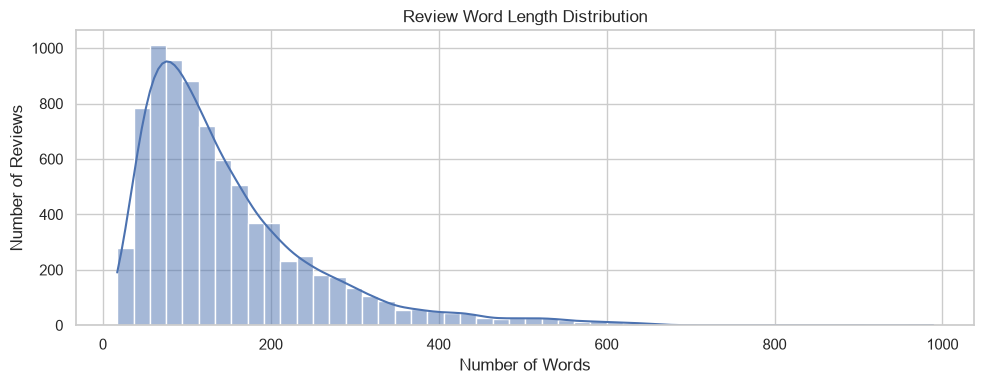

In [20]:
# Cell 19 — Review text length analysis


review_columns = [
    col for col in df.columns
    if col.lower() in {
        "reviews", "review", "review text", "text"
    }
]

for col in review_columns:

    review_text = df[col].fillna("").astype(str)

    word_lengths = review_text.str.split().str.len()
    character_lengths = review_text.str.len()

    print("\nREVIEW COLUMN:", col)

    print("\nWORD LENGTH STATISTICS:")
    display(
        word_lengths.describe(
            percentiles=[0.50, 0.75, 0.90, 0.95, 0.99]
        )
    )

    print("\nCHARACTER LENGTH STATISTICS:")
    display(character_lengths.describe())

    plt.figure(figsize=(10, 4))

    sns.histplot(
        word_lengths,
        bins=50,
        kde=True
    )

    plt.title("Review Word Length Distribution")
    plt.xlabel("Number of Words")
    plt.ylabel("Number of Reviews")
    plt.tight_layout()
    plt.show()

In [21]:
# Cell 20 — Numerical summary

print("NUMERICAL DESCRIPTIVE STATISTICS")

display(df.describe().T)

print("\nALL COLUMN DESCRIPTIVE STATISTICS")

display(df.describe(include="all").T)


NUMERICAL DESCRIPTIVE STATISTICS


,count,mean,std,min,25%,50%,75%,max
Seat Comfort,8100.0,3.414815,1.397183,1.0,2.0,4.0,5.0,5.0
Staff Service,8100.0,3.569877,1.527436,1.0,2.0,4.0,5.0,5.0
Food & Beverages,8100.0,3.384074,1.455694,1.0,2.0,4.0,5.0,5.0
Inflight Entertainment,8100.0,3.636790,1.309564,0.0,3.0,4.0,5.0,5.0
Value For Money,8100.0,3.148642,1.589377,1.0,1.0,3.0,5.0,5.0
Overall Rating,8100.0,5.632469,3.523664,1.0,2.0,6.0,9.0,10.0



ALL COLUMN DESCRIPTIVE STATISTICS


,count,unique,top,freq,mean,std,min,25%,50%,75%,max
Title,8100,7614,Turkish Airlines customer review,11,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Name,8100,6583,Michael Schade,44,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Review Date,8100,2549,2017-12-18,12,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Airline,8100,10,Turkish Airlines,1685,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Verified,8100,5,True,6216,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Reviews,8100,8099,"Unforgettable experience flying with Emirates from Singapore to Rome via Dubai. I was booked on flight EK433, with ...",2,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Type of Traveller,8100,4,Solo Leisure,3237,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Month Flown,8100,107,November 2017,150,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Route,8100,5566,Bangkok to Hong Kong,24,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Class,8100,4,Economy Class,5504,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [23]:
# Cell 21 - Date column inspection

# Identify columns that may contain dates
date_candidates = [
    col for col in df.columns
    if "date" in col.lower() or "month" in col.lower()
]

for col in date_candidates:
    print("\nCOLUMN:", col)
    print("Original dtype:", df[col].dtype)

    print("\nSample values:")
    display(df[col].dropna().head(15))

    parsed_dates = pd.to_datetime(
        df[col],
        errors="coerce"
    )

    print(
        "Successfully parsed:",
        parsed_dates.notna().sum(),
        "/",
        df[col].notna().sum()
    )



COLUMN: Review Date
Original dtype: object

Sample values:


0     2024-03-01
1     2024-02-21
2     2024-02-20
3     2024-02-19
4     2024-02-19
5     2024-02-19
6     2024-02-19
7     2024-02-19
8     2024-02-18
9     2024-02-17
10    2024-02-17
11    2024-02-16
12    2024-02-16
13    2024-02-16
14    2024-02-09
Name: Review Date, dtype: object

Successfully parsed: 8100 / 8100

COLUMN: Month Flown
Original dtype: object

Sample values:


0     December 2023
1     February 2024
2     February 2024
3     February 2024
4     February 2024
5     February 2024
6     February 2024
7     February 2024
8     February 2024
9     February 2024
10    February 2024
11    February 2024
12    February 2024
13     January 2024
14    February 2024
Name: Month Flown, dtype: object

Successfully parsed: 8100 / 8100


In [24]:
# Cell 22 — Check important categorical distributions


categorical_candidates = [
    col for col in df.columns
    if any(term in col.lower() for term in [
        "airline",
        "class",
        "traveller",
        "traveler",
        "verified",
        "route"
    ])
]

for col in categorical_candidates:
    print("\n" + "=" * 70)
    print("COLUMN:", col)
    print("UNIQUE VALUES:", df[col].nunique(dropna=True))

    print("\nTOP 15 VALUES:")
    display(df[col].value_counts(dropna=False).head(15))



COLUMN: Airline
UNIQUE VALUES: 10

TOP 15 VALUES:


Airline
Turkish Airlines          1685
Qatar Airways             1624
Emirates                  1350
Singapore Airlines         972
Air France                 798
Cathay Pacific Airways     744
EVA Air                    281
All Nippon Airways         258
Japan Airlines             201
Korean Air                 187
Name: count, dtype: int64


COLUMN: Verified
UNIQUE VALUES: 5

TOP 15 VALUES:


Verified
True                                                                                                                                                                                                                                           6216
False                                                                                                                                                                                                                                          1881
*Unverified*                                                                                                                                                                                                                                      1
NotVerified                                                                                                                                                                                                                                       1
we do appreciat


COLUMN: Type of Traveller
UNIQUE VALUES: 4

TOP 15 VALUES:


Type of Traveller
Solo Leisure      3237
Couple Leisure    1899
Family Leisure    1551
Business          1413
Name: count, dtype: int64


COLUMN: Route
UNIQUE VALUES: 5566

TOP 15 VALUES:


Route
Bangkok to Hong Kong      24
London to Singapore       23
Istanbul to London        20
Bangkok to Singapore      20
Hong Kong to Singapore    19
Singapore to Bangkok      19
Singapore to Hong Kong    18
Singapore to Sydney       17
Hong Kong to Bangkok      17
Singapore to Perth        17
Sydney to Singapore       16
Hong Kong to London       16
Perth to Singapore        16
Bangkok to Doha           16
London to Hong Kong       15
Name: count, dtype: int64


COLUMN: Class
UNIQUE VALUES: 4

TOP 15 VALUES:


Class
Economy Class      5504
Business Class     2104
Premium Economy     371
First Class         121
Name: count, dtype: int64

In [25]:
# Cell 23 — Dataset audit summary


print("=" * 65)
print("FLIGHTAURA DATASET AUDIT SUMMARY")
print("=" * 65)

print("Dataset Shape:", df.shape)
print("Total Records:", len(df))
print("Total Columns:", len(df.columns))

print("\nNumerical Columns:", len(numeric_columns))
print("Categorical/Object Columns:", len(categorical_columns))
print("Datetime Columns:", len(datetime_columns))

print("\nMissing Cells:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

print("\nTotal Memory Usage:",
      round(df.memory_usage(deep=True).sum() / (1024 ** 2), 2),
      "MB")

print("\nReview Columns:", review_columns)
print("Rating Columns:", rating_candidates)

print("\nAudit completed. No original data was modified.")


FLIGHTAURA DATASET AUDIT SUMMARY
Dataset Shape: (8100, 17)
Total Records: 8100
Total Columns: 17

Numerical Columns: 6
Categorical/Object Columns: 11
Datetime Columns: 0

Missing Cells: 0
Duplicate Rows: 0

Total Memory Usage: 15.39 MB

Review Columns: ['Reviews']
Rating Columns: ['Seat Comfort', 'Staff Service', 'Food & Beverages', 'Inflight Entertainment', 'Value For Money', 'Overall Rating']

Audit completed. No original data was modified.
